# Noise Injection — Uniform-Distribution Noise for `complex9` / `stream_densired`

Generates noisy variants of the `complex9` and `stream_densired` benchmark datasets
by **adding** uniform-random noise points on top of the clean data (no existing
points are removed or overwritten). Noise is sized so it makes up **10%, 20%, 30%,
40%, 50%** of the resulting dataset, and labeled `-1`, matching this repo's existing
convention (see `baseframework/stream_clustering.py`: "noise labels is -1").

The combined data is shuffled after adding noise so noise points are interleaved
throughout the stream rather than only appended at the end.

New files are written to both `data/` and `baseframework/data/` as
`{dataset}_noise{pct}_data.npy` / `{dataset}_noise{pct}_label.npy`. A small fallback
was added to `baseframework/datahandler.py` so these load by name, e.g.
`datahandler.load_data("complex9_noise10")` or
`src.stream_runner.load_dataset("complex9_noise10")`.

In [3]:
import sys, os

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
sys.path.insert(0, os.path.abspath("./baseframework"))

import datahandler

RNG_SEED = 0

## Noise injection

In [2]:
def inject_uniform_noise(X, y, ratio, noise_label=-1, seed=RNG_SEED):
    """Add uniform-random noise points (drawn over each feature's [min, max]
    range) on top of the clean data -- existing points are never removed or
    overwritten. `n_noise` is sized so noise makes up exactly `ratio` fraction
    of the resulting dataset. The result is shuffled so noise is interleaved
    throughout the stream rather than only appended at the end."""
    rng = np.random.default_rng(seed)
    n_noise = int(round(len(X) * ratio / (1 - ratio)))

    lo, hi = X.min(axis=0), X.max(axis=0)
    noise_points = rng.uniform(lo, hi, size=(n_noise, X.shape[1]))
    noise_labels = np.full(n_noise, noise_label, dtype=y.dtype)

    X_noisy = np.vstack([X, noise_points])
    y_noisy = np.concatenate([y, noise_labels])

    perm = rng.permutation(len(X_noisy))
    return X_noisy[perm], y_noisy[perm]

## Generate and save

In [3]:
DATASETS = ["complex9", "stream_densired"]
NOISE_RATIOS = [0.1, 0.2, 0.3, 0.4, 0.5]
OUT_DIRS = ["data", "baseframework/data"]

summary = []
for ds in DATASETS:
    X, y = datahandler.read_file(ds)  # raw, unscaled -- matches source .npy convention
    for ratio in NOISE_RATIOS:
        pct = int(round(ratio * 100))
        X_noisy, y_noisy = inject_uniform_noise(X, y, ratio)
        name = f"{ds}_noise{pct}"

        for out_dir in OUT_DIRS:
            os.makedirs(out_dir, exist_ok=True)
            np.save(os.path.join(out_dir, f"{name}_data.npy"), X_noisy)
            np.save(os.path.join(out_dir, f"{name}_label.npy"), y_noisy)

        summary.append((name, len(X_noisy), int((y_noisy == -1).sum()), ratio))

for name, n, n_noise, ratio in summary:
    print(f"{name}: N={n}, noise_points={n_noise} ({n_noise / n:.1%}), target={ratio:.0%}")

complex9_noise10: N=3368, noise_points=337 (10.0%), target=10%
complex9_noise20: N=3789, noise_points=758 (20.0%), target=20%
complex9_noise30: N=4330, noise_points=1299 (30.0%), target=30%
complex9_noise40: N=5052, noise_points=2021 (40.0%), target=40%
complex9_noise50: N=6062, noise_points=3031 (50.0%), target=50%
stream_densired_noise10: N=11111, noise_points=1111 (10.0%), target=10%
stream_densired_noise20: N=12500, noise_points=2500 (20.0%), target=20%
stream_densired_noise30: N=14286, noise_points=4286 (30.0%), target=30%
stream_densired_noise40: N=16667, noise_points=6667 (40.0%), target=40%
stream_densired_noise50: N=20000, noise_points=10000 (50.0%), target=50%


## Sanity check: round-trip through `datahandler.load_data`

In [4]:
for ds in DATASETS:
    for ratio in NOISE_RATIOS:
        pct = int(round(ratio * 100))
        name = f"{ds}_noise{pct}"
        X, y = datahandler.load_data(name)  # exercises the datahandler fallback branch
        assert X.shape[0] == y.shape[0]
        assert (y == -1).sum() > 0

print("All noisy datasets load correctly through datahandler.load_data().")

All noisy datasets load correctly through datahandler.load_data().


## Visualize

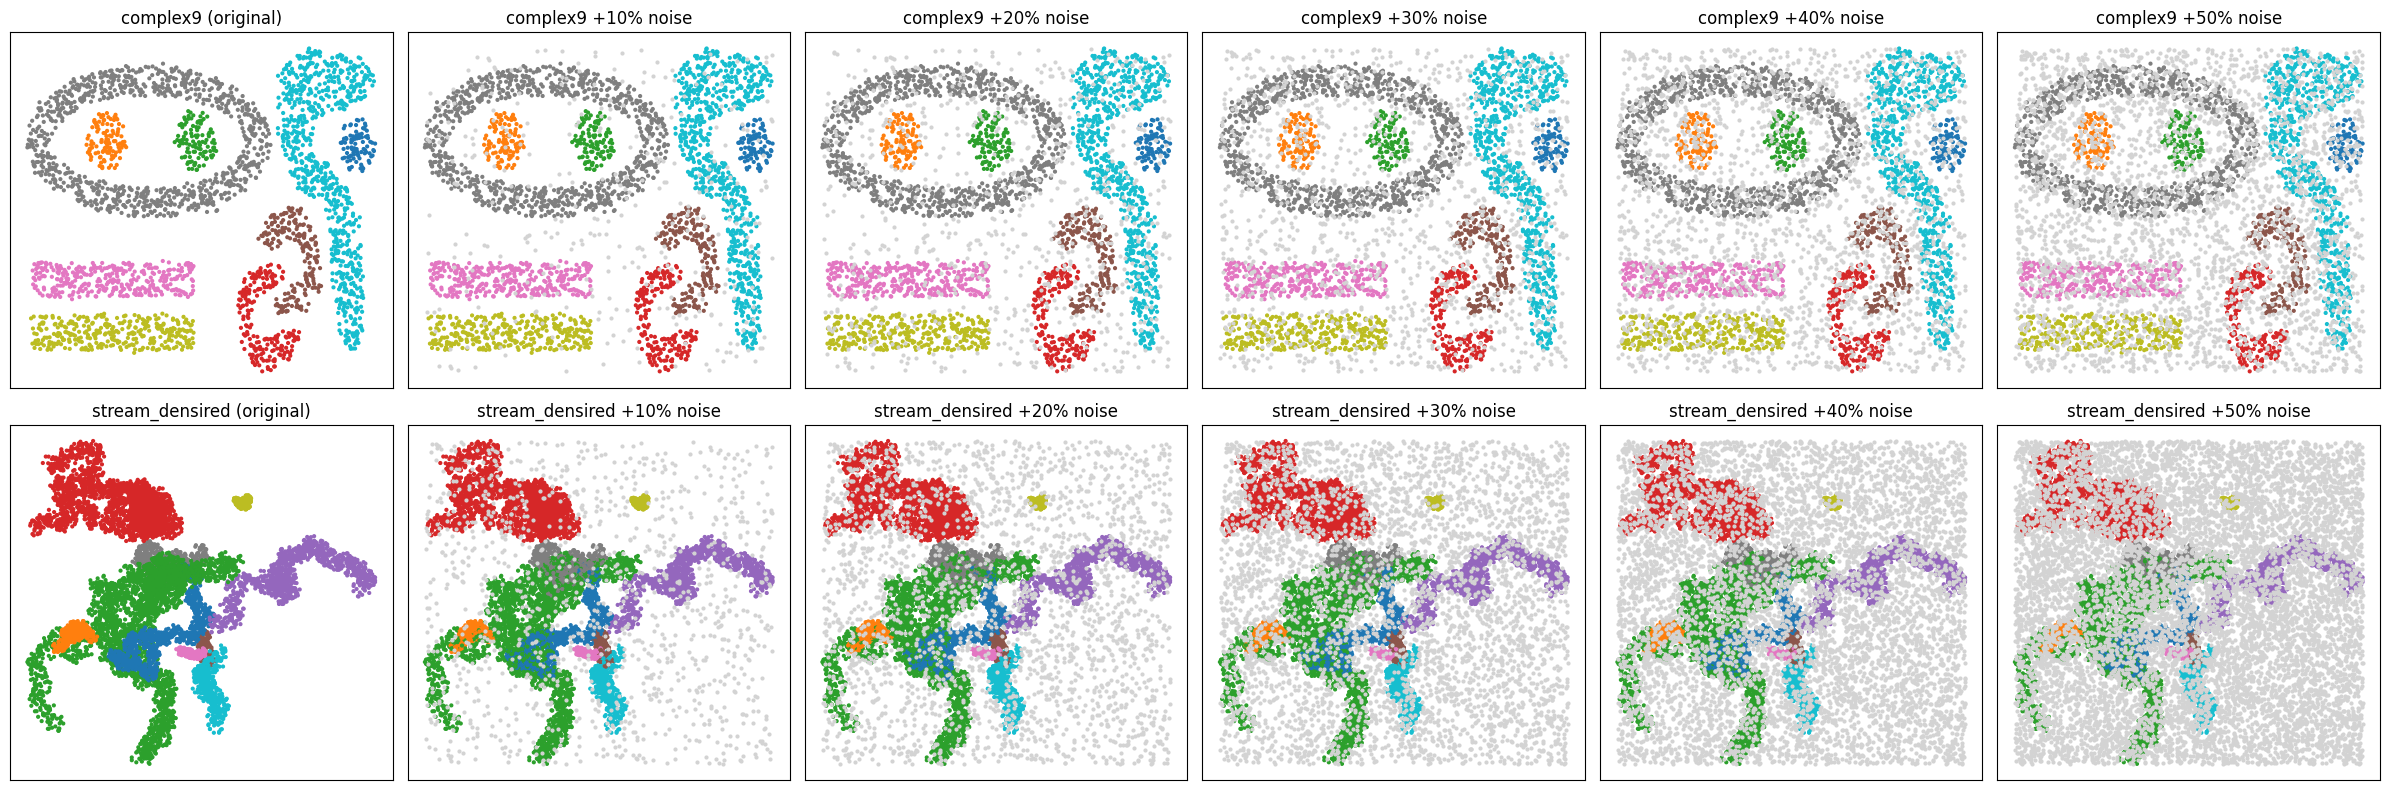

In [5]:
fig, axes = plt.subplots(len(DATASETS), len(NOISE_RATIOS) + 1,
                          figsize=(4 * (len(NOISE_RATIOS) + 1), 4 * len(DATASETS)))

for row, ds in enumerate(DATASETS):
    X0, y0 = datahandler.read_file(ds)
    axes[row, 0].scatter(X0[:, 0], X0[:, 1], c=y0, cmap="tab10", s=4)
    axes[row, 0].set_title(f"{ds} (original)")

    for col, ratio in enumerate(NOISE_RATIOS, start=1):
        pct = int(round(ratio * 100))
        Xn, yn = datahandler.load_data(f"{ds}_noise{pct}", scale=False)
        noise_mask = yn == -1
        axes[row, col].scatter(Xn[~noise_mask, 0], Xn[~noise_mask, 1],
                                c=yn[~noise_mask], cmap="tab10", s=4)
        axes[row, col].scatter(Xn[noise_mask, 0], Xn[noise_mask, 1],
                                c="lightgray", s=4)
        axes[row, col].set_title(f"{ds} +{pct}% noise")

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## Plot a single dataset

Set `DATASET_TO_PLOT` to any name loadable by `datahandler.load_data` -- one of
the originals (`"complex9"`, `"stream_densired"`, `"rbf3"`, `"har"`) or any
generated noisy variant (`"complex9_noise30"`, `"stream_densired_noise50"`, ...).

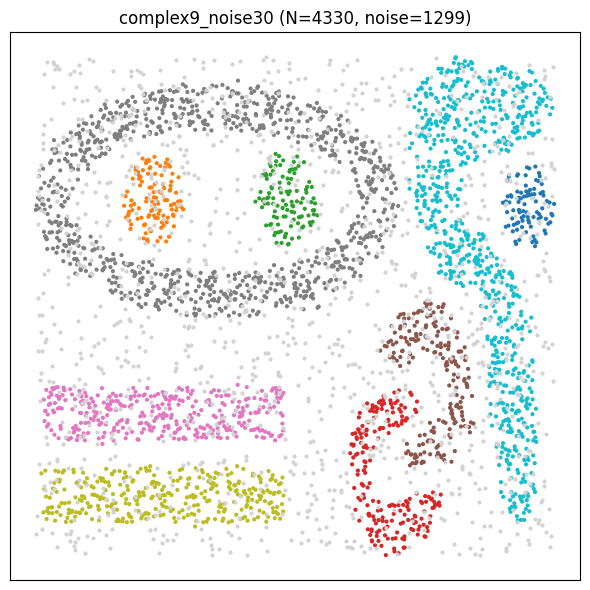

In [6]:
DATASET_TO_PLOT = "complex9_noise30"  # <-- change this

X, y = datahandler.load_data(DATASET_TO_PLOT, scale=False)
noise_mask = y == -1

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X[~noise_mask, 0], X[~noise_mask, 1], c=y[~noise_mask], cmap="tab10", s=4)
if noise_mask.any():
    ax.scatter(X[noise_mask, 0], X[noise_mask, 1], c="lightgray", s=4)
ax.set_title(f"{DATASET_TO_PLOT} (N={len(X)}, noise={noise_mask.sum()})")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

## Volume scale-up — sample more points from complex9's own distribution

Unlike the noise-injection section above, this does **not** add label `-1`
noise or alter the cluster structure. It generates a much larger synthetic
stream that follows the same per-cluster distribution as `complex9` (all 9
non-convex clusters, same relative sizes), for testing large-data-stream
behavior.

Implemented as a per-class smoothed bootstrap (~ Gaussian KDE sampling):
for each class, repeatedly pick a real point as a kernel center and add
Gaussian jitter sized by Scott's rule. This preserves complex9's non-convex
cluster shapes (moons, spirals, etc.) far better than fitting a single
parametric distribution over the whole dataset would.

Written to `data/complex9_large50_data.npy` / `..._label.npy` (loadable via
`datahandler.load_data("complex9_large50")`, same fallback branch as the
noise variants above).

In [ ]:
def sample_from_distribution(X, y, scale_factor, seed=0):
    """Generate `scale_factor`x as many points as (X, y), following the same
    per-class distribution -- a smoothed bootstrap (~ Gaussian KDE sampling):
    for each class, repeatedly pick a real point as a kernel center and add
    Gaussian jitter sized by Scott's rule. Class proportions are preserved
    exactly (every class scales by the same factor), and non-convex cluster
    shapes survive because jitter is applied locally around real points
    rather than fitting one global parametric shape."""
    rng = np.random.default_rng(seed)
    d = X.shape[1]
    X_parts, y_parts = [], []
    for label in np.unique(y):
        X_label = X[y == label]
        n_label = len(X_label)
        n_sample = n_label * scale_factor

        bandwidth = X_label.std(axis=0) * n_label ** (-1.0 / (d + 4))  # Scott's rule
        centers = X_label[rng.integers(0, n_label, size=n_sample)]
        jitter = rng.normal(0.0, 1.0, size=(n_sample, d)) * bandwidth

        X_parts.append(centers + jitter)
        y_parts.append(np.full(n_sample, label, dtype=y.dtype))

    X_big, y_big = np.vstack(X_parts), np.concatenate(y_parts)
    perm = rng.permutation(len(X_big))
    return X_big[perm], y_big[perm]


SOURCE_DATASET = "complex9"
SCALE_FACTOR = 50

X_src, y_src = datahandler.read_file(SOURCE_DATASET)  # raw, unscaled -- matches source .npy convention
X_large, y_large = sample_from_distribution(X_src, y_src, SCALE_FACTOR)
large_name = f"{SOURCE_DATASET}_large{SCALE_FACTOR}"

for out_dir in OUT_DIRS:
    os.makedirs(out_dir, exist_ok=True)
    np.save(os.path.join(out_dir, f"{large_name}_data.npy"), X_large)
    np.save(os.path.join(out_dir, f"{large_name}_label.npy"), y_large)

print(f"{large_name}: N={len(X_large)} (source N={len(X_src)}, {SCALE_FACTOR}x), "
      f"k={len(np.unique(y_large))} clusters")

# round-trip sanity check through the datahandler fallback branch
X_check, y_check = datahandler.load_data(large_name)
assert X_check.shape == X_large.shape and y_check.shape == y_large.shape
print(f"{large_name} loads correctly through datahandler.load_data().")

complex9_large50: N=151550 (source N=3031, 50x), k=9 clusters
complex9_large50 loads correctly through datahandler.load_data().


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].scatter(X_src[:, 0], X_src[:, 1], c=y_src, cmap="tab10", s=4)
axes[0].set_title(f"{SOURCE_DATASET} (original, N={len(X_src)})")
axes[1].scatter(X_large[:, 0], X_large[:, 1], c=y_large, cmap="tab10", s=1, alpha=0.3)
axes[1].set_title(f"{large_name} (N={len(X_large)})")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()